# 03 · From CATPCA to qlPCA (a short background)

Chapter 2 of the thesis [`lavado2012phd`] is a brief review of **CATPCA** (categorical PCA, [`meulman2004principal`,
`linting2007introduction`]) and of **HOMALS** (homogeneity analysis by alternating least squares, [`gifi1991nonlinear`,
`deleeuw2009homals`]), "because of the importance they had for the proposed algorithm". This notebook keeps that review short.
The focus of the repository is qlPCA for **continuous** variables; CATPCA is background and motivation.

*Contents:* 1. indicator matrices and HOMALS · 2. from HOMALS to CATPCA · 3. continuous variables in CATPCA: discretisation
(thesis §2.2.2, Example 2.2.3, Table 2.2) · 4. what qlPCA does instead · References.

> The CATPCA results quoted in the thesis (§2.2.2, chapter 4) and in the WCE paper (Table II) were computed with SPSS and are **not
> reproduced** here.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qlpca import bspline_basis, pseudo_indicator
from qlpca.plots import set_style, BLUE, ORANGE, INK, INK2, GRID

set_style()
np.set_printoptions(precision=2, suppress=True, linewidth=110)

## 1 · Indicator matrices and HOMALS

A categorical variable $h_j$ with $k_j$ categories, coded with the integers $1,\dots,k_j$, is represented by its **indicator
matrix** $G_j$ ($n\times k_j$): $G_j(i,t)=1$ if object $i$ is in category $t$, else 0. Its rows each contain one 1; its
columns are orthogonal. The thesis example is $h_1=(1,4,5,3)'$ with five categories. As the thesis notes in §3.1.1, the indicator
matrix is the matrix of the basis of *degree-0* splines, one function per category, with a knot in each gap between categories — the
**pseudo-indicator matrix** of qlPCA is this same object with another degree and other knots. The cell reproduces the thesis matrix
as degree-0 B-splines.

In [2]:
h1 = np.array([1, 4, 5, 3.0])
knots0 = np.array([1, 1.5, 2.5, 3.5, 4.5, 5])           # min, midpoints between categories 1..5, max
G1 = bspline_basis(h1, 0, knots0)
print(G1.astype(int))
print("row sums:", G1.sum(1), " column sums (frequencies):", G1.sum(0))

[[1 0 0 0 0]
 [0 0 0 1 0]
 [0 0 0 0 1]
 [0 0 1 0 0]]
row sums: [1. 1. 1. 1.]  column sums (frequencies): [1. 0. 1. 1. 1.]


**HOMALS** uses the *Multiple* treatment for every variable (each category gets $p$ coordinates, one per retained dimension)
and only piecewise-constant transformations — the indicator matrices. The loss is (1.9) of the thesis, with $M_j=G_jY_j$:

$$\sigma(X,M)=\frac1n\sum_j\operatorname{tr}\big[(X-G_jY_j)'(X-G_jY_j)\big],\qquad X'X=nI.$$

The optimal category quantification is the **centroid** of the object scores of the objects in that category (and the score of an
object is proportional to the mean of its category quantifications): the *barycentric principle* [`bekker1988relations`,
`tenenhaus1985analysis`]. The same example as above, with the barycentric step spelled out in one line of numpy:

In [3]:
X_scores = np.array([[0.2, -1.0], [1.1, 0.3], [-0.4, 0.8], [0.9, 0.5]])    # arbitrary object scores, 2 dimensions
D = G1.T @ G1                                                              # diagonal: category frequencies
Y1 = np.divide(G1.T @ X_scores, np.diag(D)[:, None], out=np.zeros((5, 2)), where=np.diag(D)[:, None] > 0)
print("category quantifications Y_1 = D^-1 G'X (empty category 2 stays 0):\n", Y1)

category quantifications Y_1 = D^-1 G'X (empty category 2 stays 0):
 [[ 0.2 -1. ]
 [ 0.   0. ]
 [ 0.9  0.5]
 [ 1.1  0.3]
 [-0.4  0.8]]


## 2 · From HOMALS to CATPCA

CATPCA generalises HOMALS in two ways: a **different treatment per variable** (Multiple or Single) and a wider class of
transformations, chosen per variable by its *optimal scaling level* [`meulman2004principal`, `linting2007introduction`]:

| optimal scaling level | admissible $f_j$ |
|---|---|
| Nominal | any quantification of the categories (piecewise constant, Single) |
| Ordinal | non-decreasing quantification |
| Numerical | linear (the standardised variable) |
| Spline nominal / spline ordinal | splines in the I-spline basis, without / with non-negative coefficients (usually $\le4$ coefficients) |
| Multiple nominal | HOMALS: $p$ quantifications per variable |

The loss function is the same common loss (1.9) for all of them (notebook 02). CATPCA's algorithm alternates between updating
the object scores and the category quantifications; for the spline levels the quantification step is a (weighted) regression on the
I-spline basis evaluated at the **categories**. Note this last point: in CATPCA the spline is a function of the *discretised* variable.

## 3 · Continuous variables in CATPCA: discretisation

In CATPCA the quantifications are computed per category, so continuous variables must be turned into categorical ones first.
SPSS's `Discretization` sub-command offers four methods [`lavado2012phd`, §2.2.2]:

* **unspecified** (default): *grouping* into 7 categories of approximately normal distribution;
* **grouping**: a chosen number of categories (normal or uniform), or equal intervals;
* **ranking**: the smallest value gets 1, and so on; the number of categories equals the number of distinct values;
* **multiplying**: standardise, multiply by 10, round to the nearest integer, add a constant so that the minimum is 1.

Example 2.2.3 of the thesis: ages recorded with different precision depending on the age (weeks below 1 year, months from 1 to 3,
quarters from 3 to 6, half-years from 6 to 12, whole years above 12). Table 2.2 shows the 32 values and their discretisation by
*multiplying* and by *ranking*. The first can be reproduced exactly (standardising with the **population** standard deviation);
the second is trivial.

In [4]:
age = np.array([0.019230769, 0.057692308, 0.076923077, 0.173076923, 0.211538462, 0.461538462, 0.480769231, 0.5,
                0.576923077, 0.596153846, 0.634615385, 0.846153846, 0.865384615, 1.083333333, 1.166666667, 1.25,
                1.333333333, 1.416666667, 1.5, 1.583333333, 2.083333333, 2.166666667, 3.25, 3.5, 3.75, 7, 7.5, 8, 8.5,
                13, 14, 15])
thesis_multiplying = np.array([1, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 4, 4, 4, 5, 5, 5, 5, 6, 7, 9, 10, 10, 18, 19, 20, 22, 32, 35, 37])

z = (age - age.mean()) / age.std(ddof=0)                  # CATPCA standardises with the population sd
multiplying = np.round(10 * z).astype(int)
multiplying = multiplying - multiplying.min() + 1
ranking = np.unique(age, return_inverse=True)[1] + 1

print("multiplying reproduces thesis Table 2.2:", bool(np.array_equal(multiplying, thesis_multiplying)))
zs = np.round(10 * (age - age.mean()) / age.std(ddof=1)).astype(int)
print("with the sample sd instead (ddof=1) it does not:", not np.array_equal(zs - zs.min() + 1, thesis_multiplying))
print("number of values:", len(age), "| categories by multiplying:", len(np.unique(multiplying)), "| by ranking:", len(np.unique(ranking)))

multiplying reproduces thesis Table 2.2: True
with the sample sd instead (ddof=1) it does not: True
number of values: 32 | categories by multiplying: 16 | by ranking: 32


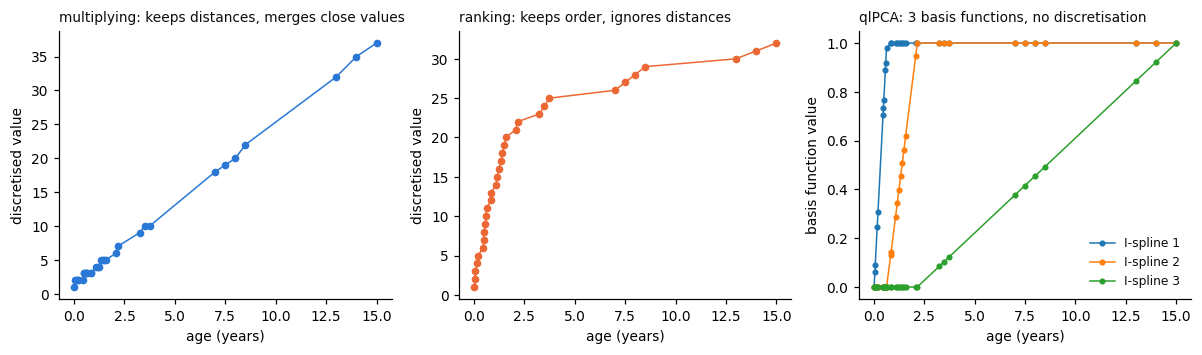

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
axes[0].plot(age, multiplying, "o-", color=BLUE, ms=4, lw=1.0); axes[0].set_title("multiplying: keeps distances, merges close values", loc="left", fontsize=9)
axes[1].plot(age, ranking, "o-", color=ORANGE, ms=4, lw=1.0); axes[1].set_title("ranking: keeps order, ignores distances", loc="left", fontsize=9)
G, kn = pseudo_indicator(age, 1, 2)
for i in range(G.shape[1]):
    axes[2].plot(age, G[:, i], "o-", ms=3, lw=1.0, label=f"I-spline {i + 1}")
axes[2].set_title("qlPCA: 3 basis functions, no discretisation", loc="left", fontsize=9)
axes[2].legend(fontsize=8)
for ax, yl in zip(axes, ("discretised value", "discretised value", "basis function value")):
    ax.set_xlabel("age (years)"); ax.set_ylabel(yl)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

*Multiplying* respects order and distance but merges values measured more precisely than the rounding allows (here the 32 values fall into only 16 categories, all the merging
happening at the young ages); *ranking* keeps every value distinct but discards the distance between consecutive values —
a difference of one week counts as much as a difference of one month. Either way, the analyst has to choose a discretisation, and the choice
affects the result. In the thesis's words, the user can also discretise outside CATPCA, using knowledge of the variable.

## 4 · What qlPCA does instead

For a continuous variable the number of categories is about the number of objects, so the per-category machinery of CATPCA is
wasteful. The idea of qlPCA (Lavado & Calapez [`lavado2011wce`, `lavado2011ijam`]) is to **drop the discretisation**: the
transformation of variable $j$ is a spline of low degree (almost always degree 1) of the *original* continuous values,
with a small number $r$ of interior knots, so the regression in the optimal-scaling step involves $w=v+r$ coefficients rather than
one per category. All variables are treated as Single; the loss is the same common loss (1.9). The remaining differences:

| | CATPCA (spline levels) | qlPCA |
|---|---|---|
| input | categorical (continuous variables discretised first) | continuous |
| transformation is a function of | the category codes | the original values |
| splines | degree and knots of the I-spline basis, **on the categories** | degree 1 by default, knots at percentiles of the data |
| treatment | Single or Multiple, per variable | Single, all variables |
| projection / reconstruction of new rows | — | yes, for degree 1 (linear interpolation of $(h_j,f_j)$, thesis §3.1.4) |

The algorithm is the subject of notebook 04.

## References

* `lavado2012phd` — N. Lavado, PhD thesis, ISCTE-IUL, 2012. Ch. 2, §2.2.2, Example 2.2.3, Table 2.2.
* `lavado2011wce`, `lavado2011ijam` — N. Lavado & T. Calapez, WCE 2011; IJAM 41(4), 2011.
* `gifi1991nonlinear` — A. Gifi, *Nonlinear Multivariate Analysis*, Wiley, 1991.
* `deleeuw2009homals` — J. de Leeuw & P. Mair, Gifi methods for optimal scaling in R: the package homals, *J. Statistical Software* 31(4), 2009.
* `meulman2004principal` — Meulman, van der Kooij & Heiser, in *Sage Handbook of Quantitative Methodology*, 2004.
* `linting2007introduction` — M. Linting, J. Meulman, P. Groenen & A. van der Kooij, Nonlinear principal components analysis: introduction and application, *Psychological Methods* 12(3), 2007.
* `bekker1988relations`, `tenenhaus1985analysis` — the barycentric principle and the relations between variants.